In [84]:
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from typing import TypedDict
import os

In [85]:
from langchain_huggingface import ChatHuggingFace, HuggingFaceEndpoint, HuggingFacePipeline
from dotenv import load_dotenv
load_dotenv()

True

In [86]:
import os
# Store Hugging Face models/cache on D: drive
os.environ["HF_HOME"] = "D:/huggingface_cache"

In [87]:
llm = HuggingFacePipeline.from_model_id(
    model_id = "Qwen/Qwen2.5-1.5B-Instruct",
    task = "text-generation",
    pipeline_kwargs = {
        "max_new_tokens": 100,
        "temperature": 0.5
    }
)

Loading weights: 100%|██████████| 338/338 [00:00<00:00, 6035.30it/s]


In [88]:
model = ChatHuggingFace(
    llm = llm
)

In [89]:
# Define State
class LLMState(TypedDict):
    question : str
    answer : str

In [90]:
def llm_qa(state : LLMState) -> LLMState:
    question = state["question"]
    prompt = f"Answer the following question {question}"
    answer = llm.invoke(prompt)
    state["answer"] = answer
    return state

In [91]:
graph = StateGraph(LLMState)
graph.add_node("LLM_Question", llm_qa)
graph.add_edge(START, "LLM_Question")
graph.add_edge("LLM_Question", END)

In [92]:
workflow = graph.compile()

In [95]:
inital_state = {
    "question" : "What is the capital of India(Answer in one line)?"
}
final_state = workflow.invoke(inital_state)
final_state

[transformers] Both `max_new_tokens` (=100) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


{'question': 'What is the capital of India(Answer in one line)?',
 'answer': 'Answer the following question What is the capital of India(Answer in one line)? New Delhi.'}

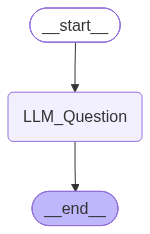

In [96]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())